In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset directly from GitHub
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Churn"].value_counts())

print("\nTarget distribution (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


Dataset shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

In [2]:

# 1. Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# 2. Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# 3. Inspect rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()])

# 4. Remove customerID
df = df.drop(columns=["customerID"])

# 5. Handle missing values
# For this dataset, missing TotalCharges occurs for zero-tenure customers.
# Remove these rows for now, after inspecting them above.
df = df.dropna(subset=["TotalCharges"]).copy()

# 6. Verify the cleaned dataset
print("\nCleaned dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nRemaining missing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["Churn"].value_counts())


Missing TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No



Cleaned dataset shape: (7032, 20)

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Remaining missing values:
0

Target distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


Churn counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


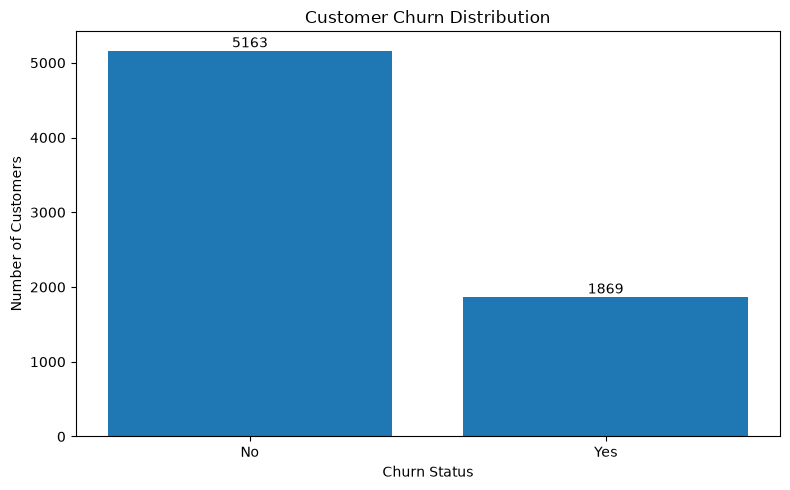

In [3]:

# 1. Calculate churn counts and percentages
churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("Churn counts:")
print(churn_counts)

print("\nChurn percentages:")
print(churn_percentages.round(2))

# 2. Plot the churn distribution
plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

# Display counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


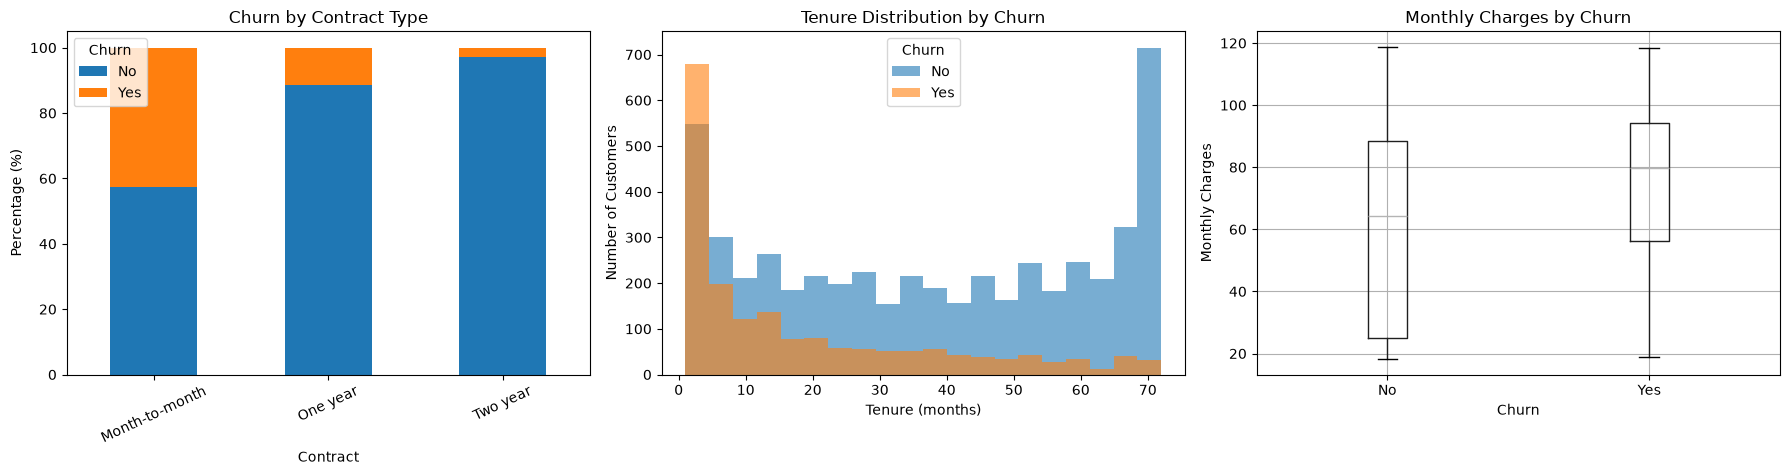

Churn rate by contract (%):
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Yes, dtype: float64


In [4]:

# Create three exploratory visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Churn rate by contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    stacked=True,
    ax=axes[0]
)

axes[0].set_title("Churn by Contract Type")
axes[0].set_xlabel("Contract")
axes[0].set_ylabel("Percentage (%)")
axes[0].legend(title="Churn")
axes[0].tick_params(axis="x", rotation=25)

# 2. Tenure distribution by churn
for status in ["No", "Yes"]:
    axes[1].hist(
        df.loc[df["Churn"] == status, "tenure"],
        bins=20,
        alpha=0.6,
        label=status
    )

axes[1].set_title("Tenure Distribution by Churn")
axes[1].set_xlabel("Tenure (months)")
axes[1].set_ylabel("Number of Customers")
axes[1].legend(title="Churn")

# 3. Monthly charges by churn
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    ax=axes[2]
)

axes[2].set_title("Monthly Charges by Churn")
axes[2].set_xlabel("Churn")
axes[2].set_ylabel("Monthly Charges")
fig.suptitle("")

plt.tight_layout()
plt.show()

# Numerical summary: churn rate by contract
print("Churn rate by contract (%):")
print(
    (pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100)
    .round(2)
)


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# 2. Identify numeric and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("\nNumber of numeric features:", len(numeric_features))
print("\nNumber of categorical features:", len(categorical_features))

# 3. Split data before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

# 4. Build preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numeric features: 4

Number of categorical features: 15

Training shape: (5625, 19)
Testing shape: (1407, 19)

Training target proportions:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Testing target proportions:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Preprocessing pipeline created successfully.


In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate class weight for XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

# Define models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# Evaluate using the training data only
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall"
}

cv_results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean CV ROC-AUC": scores["test_roc_auc"].mean(),
        "Std CV ROC-AUC": scores["test_roc_auc"].std(),
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Mean CV Precision": scores["test_precision"].mean(),
        "Mean CV Recall": scores["test_recall"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.round(4).sort_values(
        "Mean CV ROC-AUC",
        ascending=False
    )
)


,Model,Mean CV ROC-AUC,Std CV ROC-AUC,Mean CV Accuracy,Mean CV Precision,Mean CV Recall
1,XGBoost,0.8453,0.0051,0.7628,0.5380,0.7652
0,Random Forest,0.8254,0.0070,0.7756,0.5687,0.6441


,Model,Test ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1
1,XGBoost,0.8294,0.7356,0.5017,0.7781,0.6101
0,Random Forest,0.8154,0.7605,0.5414,0.6471,0.5895


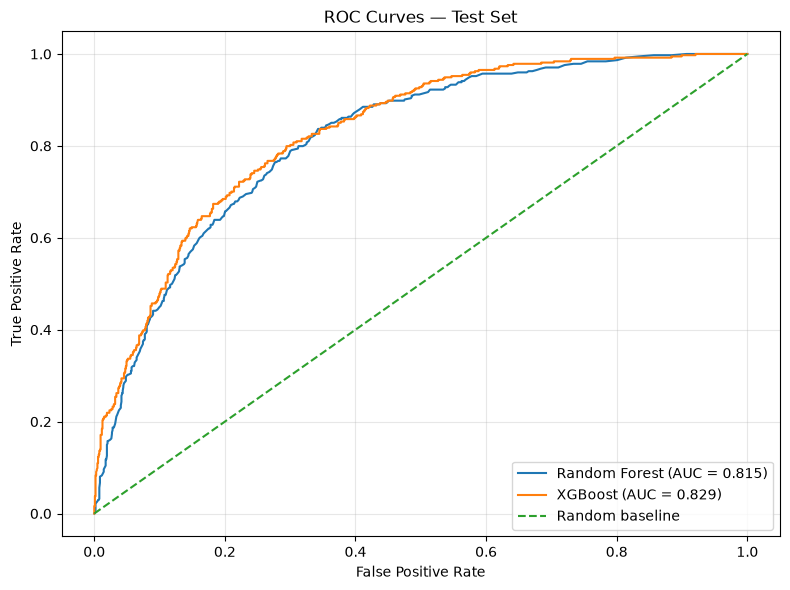

In [7]:

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Fit both complete pipelines using training data only
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

# Evaluate predictions on the untouched test set
test_results = []

for name, pipeline in fitted_models.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred),
        "Test Recall": recall_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.round(4).sort_values(
        "Test ROC-AUC",
        ascending=False
    )
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for name, pipeline in fitted_models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


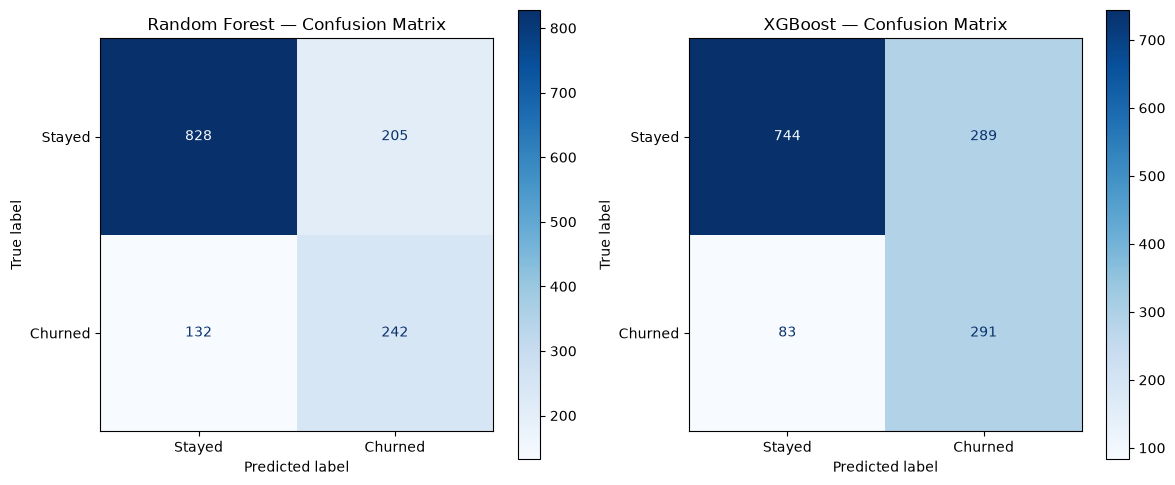

In [8]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pipeline) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        display_labels=["Stayed", "Churned"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(f"{name} — Confusion Matrix")

plt.tight_layout()
plt.show()



Top 10 features — Random Forest


,Feature,Importance
0,num__TotalCharges,0.141034
1,num__tenure,0.132027
2,num__MonthlyCharges,0.121903
3,cat__Contract_Month-to-month,0.076521
4,cat__OnlineSecurity_No,0.037804
5,cat__Contract_Two year,0.035473
6,cat__TechSupport_No,0.030841
7,cat__PaymentMethod_Electronic check,0.028448
8,cat__InternetService_Fiber optic,0.026967
9,cat__OnlineBackup_No,0.017953


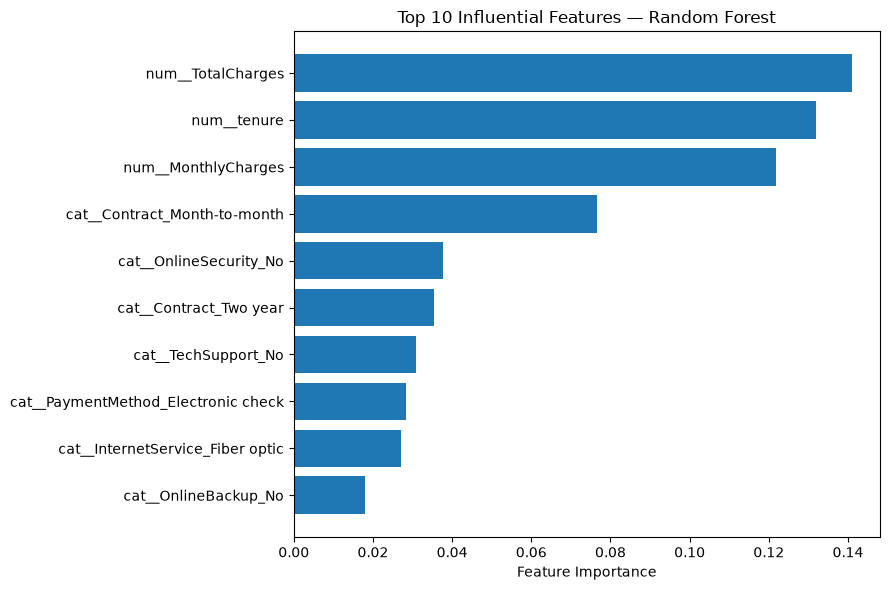


Top 10 features — XGBoost


,Feature,Importance
0,cat__Contract_Month-to-month,0.306059
1,cat__InternetService_Fiber optic,0.085783
2,cat__OnlineSecurity_No,0.057003
3,cat__OnlineBackup_No internet service,0.053241
4,cat__OnlineSecurity_No internet service,0.034268
5,cat__InternetService_No,0.030766
6,cat__Contract_Two year,0.029725
7,cat__TechSupport_No,0.027185
8,cat__InternetService_DSL,0.025239
9,cat__MultipleLines_No phone service,0.022386


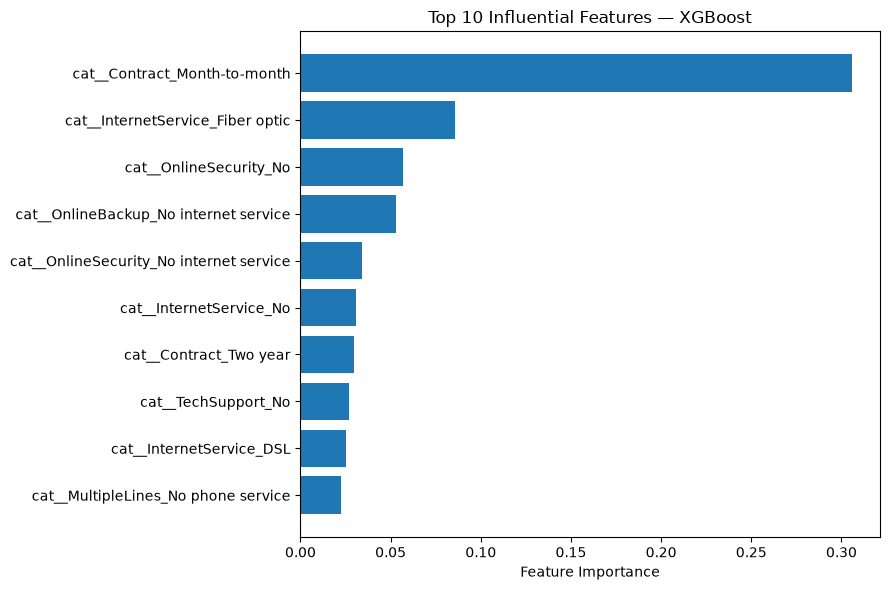

In [9]:

# Extract feature names created by the fitted preprocessing pipeline
for name, pipeline in fitted_models.items():
    feature_names = (
        pipeline.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importances = (
        pipeline.named_steps["classifier"]
        .feature_importances_
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        "Importance",
        ascending=False
    )

    top_10 = importance_df.head(10).sort_values(
        "Importance",
        ascending=True
    )

    print(f"\nTop 10 features — {name}")
    display(importance_df.head(10).reset_index(drop=True))

    plt.figure(figsize=(9, 6))
    plt.barh(top_10["Feature"], top_10["Importance"])
    plt.xlabel("Feature Importance")
    plt.title(f"Top 10 Influential Features — {name}")
    plt.tight_layout()
    plt.show()
